# Gradient Boosting Regressor — Thermal Predictor

Modelo de gradient boosting que prevê a temperatura de cada termopar (`tc_name`) de
uma `key_area` a partir das sete variáveis de configuração do ensaio.

**Um modelo por setor:** cada `key_area` recebe seu próprio modelo, treinado apenas
com os runs e os termopares daquela região — coerente com a H1 (Seção 4.2.3), em que
o efeito de uma configuração muda de sinal conforme a área.

**Entrada:** planilhas em formato wide geradas por `tratamento_final_dos_dados.ipynb`
(`data/<key_area>_data.csv`) — uma linha por run, uma coluna por termopar.

## Diferença estrutural em relação aos outros dois notebooks

`RandomForestRegressor` e `DecisionTreeRegressor` aceitam `Y` matricial nativamente:
uma folha guarda um vetor de médias, uma por termopar. **`GradientBoostingRegressor`
não** — ele exige `y` unidimensional e falha com
`ValueError: y should be a 1d array` se receber vários alvos.

A solução aqui é `MultiOutputRegressor`, que treina **um GBR independente por
termopar** e junta as previsões. Duas consequências práticas:

1. Os hiperparâmetros da grade levam o prefixo `estimator__`, porque são repassados
   ao GBR de dentro do wrapper.
2. Há uma importância de variáveis **por termopar**, e não uma única para o modelo
   inteiro — o que dá mais informação que o Random Forest, e é explorado na Célula 5.

Fora isso, a preparação dos dados e a avaliação estatística são idênticas às do
`Random_for_regre.ipynb`, para que os três modelos sejam comparáveis.

**Estrutura:** as Células 2 a 6 analisam **uma** área em detalhe — altere
`CAMINHO_PLANILHA` na Célula 2 para trocar de área. As Células 7 e 8 treinam as
**sete** de uma vez e comparam os resultados.

## 1. Bibliotecas e configuração global

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
SEMENTE = 42

## 2. Parâmetros e leitura da planilha

Formato wide: cada termopar é uma coluna-alvo independente. Tudo que não está em
`VARIAVEIS_INDEPENDENTES` é candidato a alvo.

Duas checagens são feitas na leitura, porque nem toda coluna extra é um termopar
válido: colunas **sem nome** (`Unnamed: N`, geradas quando o `tc_name` original
estava em branco — é o caso de `ct_knobs_data.csv`) e colunas **inteiramente
vazias** são descartadas com aviso, em vez de entrarem como alvo do modelo.

In [2]:
# ============================================================
# CÉLULA 2 — PARÂMETROS E LEITURA DA PLANILHA
# Formato wide: cada termopar é uma coluna-alvo independente
# ============================================================

# Troque aqui para analisar outra key_area em detalhe:
#   ../data/mainback_data.csv        ../data/ipc_comp_data.csv
#   ../data/coil_temps_data.csv      ../data/ipc_cooling_data.csv
#   ../data/main_vent_sys_data.csv   ../data/oven_hmi_data.csv
#   ../data/ct_knobs_data.csv
CAMINHO_PLANILHA = "../data/mainback_data.csv"

VARIAVEIS_INDEPENDENTES = [
    "blower_direction",
    "housing",
    "board_position",
    "run_case",
    "losses",
    "deflector_hole",
    "material_coil_support",
]

# Um termopar só entra como alvo se tiver leitura em pelo menos esta fração dos
# runs. Sensores abaixo disso são removidos como COLUNA — descartá-los custa um
# alvo, enquanto exigir que estejam presentes custaria quase todos os runs.
COBERTURA_MINIMA_ALVO = 0.50

# Número de folds do GridSearchCV. É reduzido automaticamente se o conjunto de
# treino for pequeno demais (ver Célula 5).
N_FOLDS_DESEJADO = 3


def identificar_alvos(df, independentes):
    """Separa as colunas-alvo válidas das colunas que não representam termopar."""
    alvos, descartadas = [], []
    for coluna in df.columns:
        if coluna in independentes:
            continue
        if str(coluna).startswith("Unnamed:") or not str(coluna).strip():
            descartadas.append((coluna, "coluna sem nome de termopar"))
        elif df[coluna].isna().all():
            descartadas.append((coluna, "coluna inteiramente vazia"))
        else:
            alvos.append(coluna)
    return alvos, descartadas


def resumir_alvos(df, alvos):
    """Tabela de cobertura e estatística descritiva de cada termopar."""
    return pd.DataFrame([
        {
            "termopar": alvo,
            "leituras": int(df[alvo].notna().sum()),
            "cobertura": df[alvo].notna().mean(),
            "min": df[alvo].min(),
            "max": df[alvo].max(),
            "média": df[alvo].mean(),
            "desvio": df[alvo].std(),
        }
        for alvo in alvos
    ]).sort_values("cobertura", ascending=False, ignore_index=True)


def listar_alvos_duplicados(df, alvos):
    """Pares de termopares com leitura idêntica (possível duplicação de sensor)."""
    return [
        (alvo_a, alvo_b)
        for i, alvo_a in enumerate(alvos)
        for alvo_b in alvos[i + 1:]
        if df[alvo_a].equals(df[alvo_b])
    ]


dados = pd.read_csv(CAMINHO_PLANILHA)
VARIAVEIS_ALVO, COLUNAS_DESCARTADAS = identificar_alvos(dados, VARIAVEIS_INDEPENDENTES)

print(f"Arquivo: {CAMINHO_PLANILHA}")
print(f"Linhas: {len(dados)} | Colunas: {dados.shape[1]}")

if COLUNAS_DESCARTADAS:
    print("\nColunas ignoradas (não são termopares válidos):")
    for coluna, motivo in COLUNAS_DESCARTADAS:
        print(f"   {coluna!r}: {motivo}")

print(f"\nTermopares candidatos ({len(VARIAVEIS_ALVO)}):")
print(resumir_alvos(dados, VARIAVEIS_ALVO).round(2).to_string(index=False))

print(f"\nValores nulos nos alvos: {int(dados[VARIAVEIS_ALVO].isna().sum().sum())}")

duplicadas = listar_alvos_duplicados(dados, VARIAVEIS_ALVO)
if duplicadas:
    print("\nATENÇÃO — colunas-alvo com valores idênticos:")
    for alvo_a, alvo_b in duplicadas:
        print(f"   {alvo_a}  ==  {alvo_b}")

dados.head()

Arquivo: ../data/mainback_data.csv
Linhas: 32 | Colunas: 17

Termopares candidatos (10):
                          termopar  leituras  cobertura   min    max  média  desvio
       ACU Ambient (Hill Only) Top        32        1.0 49.92  99.06  61.45   12.28
ACU K8 Housing / Double Line Break        32        1.0 44.00  68.08  49.45    7.30
      Ambient Below Terminal Block        32        1.0 39.56  73.91  47.02    8.98
             Convect Motor Winding        32        1.0 73.63 103.87  84.19    8.19
        Door Lock Microswitch Body        32        1.0 85.54 118.55  96.18    6.41
Door Lock Motor Ambient 1/2" Below        32        1.0 77.50 102.88  91.80    4.91
        Hot Surface Indicator Body        32        1.0 39.22  60.48  43.82    4.17
              L2, Wire, Power Cord        32        1.0 43.63  77.33  50.85    9.29
           Power On Indicator Body        32        1.0 38.34  55.30  43.61    3.01
      Storage Drawer (Metal Above)        32        1.0 93.97 171.57 10

,blower_direction,housing,board_position,run_case,losses,deflector_hole,material_coil_support,ACU Ambient (Hill Only) Top,ACU K8 Housing / Double Line Break,Ambient Below Terminal Block,Convect Motor Winding,Door Lock Microswitch Body,"Door Lock Motor Ambient 1/2"" Below",Hot Surface Indicator Body,"L2, Wire, Power Cord",Power On Indicator Body,Storage Drawer (Metal Above)
0,To back,Closed,Center,Broil C2,Simone Losses,Open,Aluminium,58.07,45.7700,45.3700,81.950,99.1100,90.740,45.22,47.7200,43.0200,96.11
1,To back,Closed,Center,Broil C2,Simone Modified - Back Order,Closed,Aluminium,64.03,48.7600,46.6500,87.910,105.6800,98.050,44.29,50.5700,42.5700,100.54
2,To back,Closed,Center,Broil Qualitative,Simone Losses,Open,Aluminium,57.59,45.2300,42.8500,81.040,98.1700,90.780,43.06,45.9300,44.2400,95.95
3,To back,Open,Center,Broil C2,Simone Losses,Open,Aluminium,82.45,66.4475,70.9875,99.955,85.5425,77.495,42.92,73.8175,40.0575,95.10
4,To back,Open,Center,Broil C2,Simone Modified - Back Order,Closed,Aluminium,83.34,66.3900,62.8500,100.590,94.0300,84.870,47.97,70.9000,44.5100,100.10


## 3. Seleção de alvos, padronização das categorias e codificação

Primeiro descarta o **sensor** de cobertura baixa (coluna), depois descarta as
**linhas** que ainda tenham buraco entre os alvos que sobraram. A ordem importa:
fazer `dropna` direto sobre todos os alvos é *listwise deletion* — basta um sensor
pouco medido para eliminar quase todos os runs. Em `main_vent_sys_data.csv`, dois
sensores medidos em apenas 4 dos 56 runs derrubariam a base de 56 para 4 linhas.

Idêntico ao `Random_for_regre.ipynb`, de propósito: as três abordagens precisam
partir exatamente da mesma base para que a comparação de métricas faça sentido.

In [3]:
# ============================================================
# CÉLULA 3 — SELEÇÃO DE ALVOS, PADRONIZAÇÃO E CODIFICAÇÃO ONE-HOT
# ============================================================
GRAFIAS_DIVERGENTES = {
    "blower_direction": {"To back": "To Back", "To front": "To Front"},
    "losses":           {"No losses": "No Losses"},
    "run_case":         {"Broil Case 2": "Broil C2", "Broil Qual": "Broil Qualitative", "Qualitative": "Broil Qualitative"},
    "housing":          {"Open - Updated": "Open"},
    # O glossario oficial do parceiro so documenta 2 niveis para Material Coil
    # Support (Aluminium / Plastic). 1 run (48) ja vinha rotulado "Aluminium
    # Plate" no dado bruto, antes de qualquer reclassificacao nossa - sem
    # confirmacao fisica desse nivel extra, normaliza de volta para Aluminium
    # (ver documents/extras/hipotese_material_sem_correcao_E17.md).
    "material_coil_support": {"Aluminium Plate": "Aluminium "},
}


def filtrar_alvos_por_cobertura(df, alvos, cobertura_minima):
    """Mantém apenas os termopares medidos em uma fração mínima dos runs."""
    mantidos, removidos = [], []
    for alvo in alvos:
        cobertura = df[alvo].notna().mean()
        if cobertura >= cobertura_minima:
            mantidos.append(alvo)
        else:
            removidos.append((alvo, int(df[alvo].notna().sum()), cobertura))
    return mantidos, removidos


def padronizar_categorias(df, independentes, correcoes_por_variavel):
    """Unifica grafias divergentes e transforma nulos em categoria explícita."""
    df = df.copy()
    for variavel, correcoes in correcoes_por_variavel.items():
        if variavel in df.columns:
            df[variavel] = df[variavel].replace(correcoes)
    for variavel in independentes:
        df[variavel] = df[variavel].fillna("Nao Informado").astype(str)
    return df


def codificar_onehot(df, independentes):
    """Codificação one-hot: uma coluna binária por categoria observada."""
    X = pd.get_dummies(df[independentes].astype(str), columns=independentes).astype(int)
    dicionario = {
        variavel: sorted(df[variavel].astype(str).unique())
        for variavel in independentes
    }
    return X, dicionario


# 1) Descarta o SENSOR pouco medido (coluna), não o run (linha).
VARIAVEIS_ALVO, alvos_removidos = filtrar_alvos_por_cobertura(
    dados, VARIAVEIS_ALVO, COBERTURA_MINIMA_ALVO
)

if alvos_removidos:
    print(f"Termopares removidos por cobertura < {COBERTURA_MINIMA_ALVO:.0%}:")
    for alvo, leituras, cobertura in alvos_removidos:
        print(f"   {alvo:40s} {leituras:3d}/{len(dados)} runs ({cobertura:.1%})")
    print()

if not VARIAVEIS_ALVO:
    raise ValueError(
        f"Nenhum termopar atingiu a cobertura mínima de {COBERTURA_MINIMA_ALVO:.0%}. "
        f"Reduza COBERTURA_MINIMA_ALVO na Célula 2 para modelar este arquivo."
    )

# 2) Só agora descarta as LINHAS com buraco entre os alvos que sobraram.
dados_tratados = dados.dropna(subset=VARIAVEIS_ALVO).copy()

linhas_removidas = len(dados) - len(dados_tratados)
if linhas_removidas:
    print(f"Linhas removidas por alvo ausente: {linhas_removidas}\n")

dados_tratados = padronizar_categorias(
    dados_tratados, VARIAVEIS_INDEPENDENTES, GRAFIAS_DIVERGENTES
)
X, dicionario_codificacao = codificar_onehot(dados_tratados, VARIAVEIS_INDEPENDENTES)
Y = dados_tratados[VARIAVEIS_ALVO]

print("Categorias por variável (uma coluna one-hot por categoria):\n")
for variavel, categorias in dicionario_codificacao.items():
    print(f"{variavel} ({len(categorias)} categorias)")
    for categoria in categorias:
        print(f"   {variavel}_{categoria}")
    print()

print(f"Matriz de features: {X.shape}")
print(f"Colunas-alvo: {len(VARIAVEIS_ALVO)}")
print(f"Linhas úteis: {len(dados_tratados)} de {len(dados)}")
print(f"Combinações distintas de configuração: {X.drop_duplicates().shape[0]}")

Categorias por variável (uma coluna one-hot por categoria):

blower_direction (2 categorias)
   blower_direction_To Back
   blower_direction_To Front

housing (2 categorias)
   housing_Closed
   housing_Open

board_position (2 categorias)
   board_position_Center
   board_position_Right

run_case (4 categorias)
   run_case_Broil C1
   run_case_Broil C2
   run_case_Broil Qualitative
   run_case_Pyro

losses (13 categorias)
   losses_Broil C2 Simone - 240/145/180/180
   losses_Broil C2 Simone - Front Order
   losses_Broil Miro - Front Order
   losses_C1 Simone - 240/145/180/180
   losses_Miro
   losses_Miro - Front Order
   losses_Miro Qualitative  - Back Order
   losses_Miro Qualitative  - Front Order
   losses_No Losses
   losses_Qual Simone - Front Order
   losses_Simone
   losses_Simone Losses
   losses_Simone Modified - Back Order

deflector_hole (2 categorias)
   deflector_hole_Closed
   deflector_hole_Open

material_coil_support (2 categorias)
   material_coil_support_Aluminium 
 

## 4. Separação treino (70%) / teste (20%) / verificação (10%)

`Y` é matricial: uma coluna por termopar, lida de `dados_tratados` para permanecer
alinhada com as linhas de `X`. O `MultiOutputRegressor` da Célula 5 se encarrega de
quebrar essa matriz em um problema por termopar.

A célula checa antes da divisão se sobraram linhas suficientes para formar os três
conjuntos e ainda alimentar a validação cruzada, falhando com uma mensagem que diz
o que ajustar — em vez do `ValueError` genérico do `GridSearchCV`.

In [4]:
# ============================================================
# CÉLULA 4 — SEPARAÇÃO TREINO (70%) / TESTE (20%) / VERIFICAÇÃO (10%)
# Y é matricial (uma coluna por termopar)
# ============================================================
PROPORCAO_TREINO = 0.70
PROPORCAO_TESTE = 0.20
PROPORCAO_VERIFICACAO = 0.10

MINIMO_DE_LINHAS = 10
if len(X) < MINIMO_DE_LINHAS:
    raise ValueError(
        f"Apenas {len(X)} linhas úteis após o tratamento — insuficiente para dividir em "
        f"treino/teste/verificação e rodar validação cruzada. Verifique a Célula 3: "
        f"provavelmente há termopares esparsos derrubando linhas. Considere reduzir "
        f"COBERTURA_MINIMA_ALVO (hoje {COBERTURA_MINIMA_ALVO:.0%}) na Célula 2."
    )

X_treino, X_restante, Y_treino, Y_restante = train_test_split(
    X, Y,
    train_size=PROPORCAO_TREINO,
    random_state=SEMENTE,
)

proporcao_verificacao_no_restante = (
    PROPORCAO_VERIFICACAO / (PROPORCAO_TESTE + PROPORCAO_VERIFICACAO)
)

X_teste, X_verificacao, Y_teste, Y_verificacao = train_test_split(
    X_restante, Y_restante,
    test_size=proporcao_verificacao_no_restante,
    random_state=SEMENTE,
)

print(f"Treino:       {len(X_treino):3d} linhas ({len(X_treino)/len(X):.1%})")
print(f"Teste:        {len(X_teste):3d} linhas ({len(X_teste)/len(X):.1%})")
print(f"Verificação:  {len(X_verificacao):3d} linhas ({len(X_verificacao)/len(X):.1%})")
print(f"\nFormato de X: {X_treino.shape}  |  Formato de Y: {Y_treino.shape}")
print(f"Modelos que serão treinados nesta área: {Y_treino.shape[1]} "
      f"(um GBR por termopar)")

Treino:        22 linhas (68.8%)
Teste:          6 linhas (18.8%)
Verificação:    4 linhas (12.5%)

Formato de X: (22, 27)  |  Formato de Y: (22, 10)
Modelos que serão treinados nesta área: 10 (um GBR por termopar)


## 5. Treinamento do modelo (Gradient Boosting, um GBR por termopar)

`MultiOutputRegressor` envolve o `GradientBoostingRegressor` e treina um regressor
independente por termopar — é o que torna o GBR utilizável neste dataset multi-alvo.
Por isso os parâmetros da grade levam o prefixo `estimator__`.

A grade é a de controle de superajuste que interessa em boosting: `learning_rate` e
`n_estimators` (que se compensam — taxa menor exige mais estágios), `max_depth`
raso (2 ou 3, o padrão em boosting é somar muitos aprendizes fracos, não poucos
fortes) e `subsample` < 1 para introduzir estocasticidade, útil com ~40 linhas.

`n_jobs` fica no `GridSearchCV`, e o `MultiOutputRegressor` roda em série, para não
disputar núcleos entre os dois níveis de paralelismo.

**Custo:** esta é a célula mais lenta dos três notebooks — 16 combinações × 3 folds ×
um GBR por termopar. Em `ipc_comp_data.csv` (37 termopares) leva cerca de 80 s.

In [5]:
# ============================================================
# CÉLULA 5 — TREINAMENTO (GRADIENT BOOSTING, UM GBR POR TERMOPAR)
# GradientBoostingRegressor não aceita Y matricial: MultiOutputRegressor
# treina um regressor independente para cada termopar.
# ============================================================
GRADE_HIPERPARAMETROS = {
    "estimator__n_estimators":  [100, 300],
    "estimator__learning_rate": [0.05, 0.1],
    "estimator__max_depth":     [2, 3],
    "estimator__subsample":     [1.0, 0.8],
}

# Nunca pedir mais folds do que há linhas de treino.
n_folds = max(2, min(N_FOLDS_DESEJADO, len(X_treino)))
if n_folds < N_FOLDS_DESEJADO:
    print(f"Aviso: {len(X_treino)} linhas de treino — usando {n_folds} folds "
          f"em vez de {N_FOLDS_DESEJADO}.\n")

busca = GridSearchCV(
    estimator=MultiOutputRegressor(
        GradientBoostingRegressor(random_state=SEMENTE), n_jobs=1
    ),
    param_grid=GRADE_HIPERPARAMETROS,
    cv=n_folds,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
)
busca.fit(X_treino, Y_treino)

modelo = busca.best_estimator_

print("Melhores hiperparâmetros:")
for parametro, valor in busca.best_params_.items():
    print(f"   {parametro.replace('estimator__', '')}: {valor}")

print(f"\nRegressores treinados: {len(modelo.estimators_)} (um por termopar)")


def importancias_por_alvo(modelo_multioutput, colunas_onehot, independentes, alvos):
    """Matriz termopar x variável — soma a importância das colunas one-hot de
    volta para a variável original (cada categoria virou uma coluna binária)."""
    bruta = pd.DataFrame(
        [estimador.feature_importances_ for estimador in modelo_multioutput.estimators_],
        index=alvos,
        columns=colunas_onehot,
    )

    def variavel_original(coluna):
        candidatos = [v for v in independentes if coluna.startswith(v + "_")]
        return max(candidatos, key=len)

    mapa_variavel = {coluna: variavel_original(coluna) for coluna in colunas_onehot}
    return bruta.T.groupby(mapa_variavel).sum().T


matriz_importancia = importancias_por_alvo(modelo, X.columns, VARIAVEIS_INDEPENDENTES, VARIAVEIS_ALVO)
importancia = matriz_importancia.mean().sort_values(ascending=False)

print(f"\nImportância média das variáveis (entre os {len(VARIAVEIS_ALVO)} termopares):")
print(importancia.round(4).to_string())



print("Termopar mais sensível a cada variável:")
for variavel in importancia.index:
    alvo = matriz_importancia[variavel].idxmax()
    print(f"   {variavel:24s} -> {alvo} ({matriz_importancia.loc[alvo, variavel]:.3f})")

Melhores hiperparâmetros:
   learning_rate: 0.05
   max_depth: 3
   n_estimators: 100
   subsample: 0.8

Regressores treinados: 10 (um por termopar)

Importância média das variáveis (entre os 10 termopares):
run_case                 0.3286
blower_direction         0.3081
housing                  0.1588
losses                   0.1107
deflector_hole           0.0517
board_position           0.0396
material_coil_support    0.0025
Termopar mais sensível a cada variável:
   run_case                 -> Storage Drawer (Metal Above) (0.836)
   blower_direction         -> L2, Wire, Power Cord (0.512)
   housing                  -> ACU K8 Housing / Double Line Break (0.289)
   losses                   -> Door Lock Motor Ambient 1/2" Below (0.198)
   deflector_hole           -> Power On Indicator Body (0.120)
   board_position           -> ACU Ambient (Hill Only) Top (0.358)
   material_coil_support    -> Door Lock Microswitch Body (0.014)


## 6. Avaliação estatística por termopar

MAE, MSE, RMSE, R² e MAPE calculados coluna a coluna nos três conjuntos, seguidos
da média entre termopares e da fração de previsões dentro da margem de 10%
acordada com o parceiro. Idêntica à do `Random_for_regre.ipynb`.

In [6]:
# ============================================================
# CÉLULA 6 — AVALIAÇÃO ESTATÍSTICA POR TERMOPAR
# ============================================================
def avaliar_multioutput(Y_real, Y_previsto, nome_conjunto, alvos):
    """Calcula métricas para cada coluna-alvo separadamente."""
    linhas = []
    for indice, termopar in enumerate(alvos):
        real = Y_real.iloc[:, indice].values
        previsto = Y_previsto[:, indice]
        mse = mean_squared_error(real, previsto)
        linhas.append({
            "conjunto": nome_conjunto,
            "termopar": termopar,
            "MAE":      mean_absolute_error(real, previsto),
            "MSE":      mse,
            "RMSE":     np.sqrt(mse),
            "R2":       r2_score(real, previsto),
            "MAPE_%":   np.mean(np.abs((real - previsto) / real)) * 100,
        })
    return linhas


previsoes_treino      = modelo.predict(X_treino)
previsoes_teste       = modelo.predict(X_teste)
previsoes_verificacao = modelo.predict(X_verificacao)

avaliacao = pd.DataFrame(
    avaliar_multioutput(Y_treino,      previsoes_treino,      "Treino",      VARIAVEIS_ALVO)
  + avaliar_multioutput(Y_teste,       previsoes_teste,       "Teste",       VARIAVEIS_ALVO)
  + avaliar_multioutput(Y_verificacao, previsoes_verificacao, "Verificação", VARIAVEIS_ALVO)
)

print("=" * 100)
print(f"DESEMPENHO POR TERMOPAR — {CAMINHO_PLANILHA}")
print("=" * 100)
print(avaliacao.round(4).to_string(index=False))

print("\n" + "=" * 100)
print("MÉDIA ENTRE OS TERMOPARES")
print("=" * 100)
resumo_conjuntos = (
    avaliacao.groupby("conjunto", sort=False)[["MAE", "MSE", "RMSE", "R2", "MAPE_%"]]
             .mean()
)
print(resumo_conjuntos.round(4).to_string())

erro_percentual_teste = np.abs((Y_teste.values - previsoes_teste) / Y_teste.values)
print(f"\nPrevisões dentro da margem de 10% (teste, todos os termopares): "
      f"{(erro_percentual_teste <= 0.10).mean():.1%}")

# Gap treino -> teste: leitura direta de superajuste (risco R03 da Seção 4.1.5).
gap = resumo_conjuntos.loc["Teste", "MAE"] - resumo_conjuntos.loc["Treino", "MAE"]
print(f"Gap de MAE treino -> teste: {gap:+.2f} °C")

DESEMPENHO POR TERMOPAR — ../data/mainback_data.csv
   conjunto                           termopar     MAE      MSE    RMSE        R2  MAPE_%
     Treino        ACU Ambient (Hill Only) Top  0.8348   1.1067  1.0520    0.9940  1.2648
     Treino ACU K8 Housing / Double Line Break  0.2018   0.0654  0.2557    0.9990  0.3740
     Treino       Ambient Below Terminal Block  0.3489   0.1698  0.4120    0.9984  0.7044
     Treino              Convect Motor Winding  0.2996   0.1296  0.3599    0.9984  0.3500
     Treino         Door Lock Microswitch Body  0.5979   0.5051  0.7107    0.9904  0.6197
     Treino Door Lock Motor Ambient 1/2" Below  0.4568   0.2677  0.5174    0.9917  0.5078
     Treino         Hot Surface Indicator Body  0.3713   0.2290  0.4785    0.9897  0.8375
     Treino               L2, Wire, Power Cord  0.2180   0.0958  0.3095    0.9991  0.3950
     Treino            Power On Indicator Body  0.3579   0.1819  0.4265    0.9823  0.8146
     Treino       Storage Drawer (Metal Above)  

## 7. Um modelo por setor — treino das sete áreas

Encadeia as funções das células anteriores em um único pipeline e treina um conjunto
independente de GBRs para cada `key_area`. Os modelos ficam guardados em
`MODELOS_POR_AREA`, junto com os alvos e o dicionário de codificação de cada um — o
conjunto necessário para servir previsões no dashboard.

Esta célula treina, ao todo, um GBR para cada termopar de cada área (74 no total nas
sete planilhas), cada um com busca de hiperparâmetros. Leva alguns minutos.

In [7]:
# ============================================================
# CÉLULA 7 — UM MODELO POR SETOR (KEY_AREA)
# ============================================================
PLANILHAS = [
    "../data/mainback_data.csv",
    "../data/coil_temps_data.csv",
    "../data/main_vent_sys_data.csv",
    "../data/ct_knobs_data.csv",
    "../data/ipc_comp_data.csv",
    "../data/ipc_cooling_data.csv",
    "../data/oven_hmi_data.csv",
]


def preparar_area(caminho, cobertura_minima=COBERTURA_MINIMA_ALVO):
    """Leitura + seleção de alvos + codificação de uma planilha. Devolve X, Y e metadados."""
    df = pd.read_csv(caminho)
    alvos, _ = identificar_alvos(df, VARIAVEIS_INDEPENDENTES)
    alvos, removidos = filtrar_alvos_por_cobertura(df, alvos, cobertura_minima)
    if not alvos:
        raise ValueError(f"{caminho}: nenhum termopar com cobertura >= {cobertura_minima:.0%}")

    tratado = df.dropna(subset=alvos)
    tratado = padronizar_categorias(tratado, VARIAVEIS_INDEPENDENTES, GRAFIAS_DIVERGENTES)
    X_area, dicionario = codificar_onehot(tratado, VARIAVEIS_INDEPENDENTES)
    return X_area, tratado[alvos], alvos, dicionario, removidos


def treinar_area(caminho, n_folds_desejado=N_FOLDS_DESEJADO):
    """Treina os GBRs de uma key_area e devolve o modelo com suas métricas."""
    X_area, Y_area, alvos, dicionario, removidos = preparar_area(caminho)

    if len(X_area) < MINIMO_DE_LINHAS:
        raise ValueError(f"{caminho}: apenas {len(X_area)} linhas úteis")

    X_tr, X_resto, Y_tr, Y_resto = train_test_split(
        X_area, Y_area, train_size=PROPORCAO_TREINO, random_state=SEMENTE)
    X_te, X_ve, Y_te, Y_ve = train_test_split(
        X_resto, Y_resto,
        test_size=PROPORCAO_VERIFICACAO / (PROPORCAO_TESTE + PROPORCAO_VERIFICACAO),
        random_state=SEMENTE)

    modelo_area = GridSearchCV(
        estimator=MultiOutputRegressor(
            GradientBoostingRegressor(random_state=SEMENTE), n_jobs=1
        ),
        param_grid=GRADE_HIPERPARAMETROS,
        cv=max(2, min(n_folds_desejado, len(X_tr))),
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    ).fit(X_tr, Y_tr).best_estimator_

    metricas = pd.DataFrame(
        avaliar_multioutput(Y_tr, modelo_area.predict(X_tr), "Treino", alvos)
      + avaliar_multioutput(Y_te, modelo_area.predict(X_te), "Teste", alvos)
      + avaliar_multioutput(Y_ve, modelo_area.predict(X_ve), "Verificação", alvos)
    )
    medias = metricas.groupby("conjunto", sort=False)[["MAE", "RMSE", "R2", "MAPE_%"]].mean()
    erro_pct = np.abs((Y_te.values - modelo_area.predict(X_te)) / Y_te.values)

    resumo = {
        "setor": caminho.split("/")[-1].replace("_data.csv", ""),
        "linhas": len(X_area),
        "alvos": len(alvos),
        "alvos_removidos": len(removidos),
        "MAE_treino": medias.loc["Treino", "MAE"],
        "MAE_teste": medias.loc["Teste", "MAE"],
        "RMSE_teste": medias.loc["Teste", "RMSE"],
        "R2_teste": medias.loc["Teste", "R2"],
        "MAPE_teste_%": medias.loc["Teste", "MAPE_%"],
        "dentro_de_10%": (erro_pct <= 0.10).mean(),
    }
    detalhe = {
        "modelo": modelo_area,
        "alvos": alvos,
        "codificacao": dicionario,
        "metricas": metricas,
        "importancias": importancias_por_alvo(modelo_area, X_area.columns, VARIAVEIS_INDEPENDENTES, alvos),
    }
    return resumo, detalhe


MODELOS_POR_AREA = {}
resumos = []

for caminho in PLANILHAS:
    try:
        resumo, detalhe = treinar_area(caminho)
        MODELOS_POR_AREA[resumo["setor"]] = detalhe
        resumos.append(resumo)
        print(f"OK    {resumo['setor']:15s} "
              f"{resumo['linhas']:3d} linhas, {resumo['alvos']:2d} GBRs treinados")
    except Exception as erro:
        print(f"FALHA {caminho}: {type(erro).__name__}: {erro}")

total_gbrs = sum(r["alvos"] for r in resumos)
print(f"\n{len(MODELOS_POR_AREA)} setores modelados, {total_gbrs} GBRs no total: "
      f"{list(MODELOS_POR_AREA)}")

OK    mainback         32 linhas, 10 GBRs treinados


OK    coil_temps       32 linhas,  8 GBRs treinados


OK    main_vent_sys    32 linhas,  7 GBRs treinados


OK    ct_knobs         32 linhas,  6 GBRs treinados


OK    ipc_comp         32 linhas, 22 GBRs treinados


OK    ipc_cooling      32 linhas,  4 GBRs treinados


OK    oven_hmi         32 linhas,  4 GBRs treinados

7 setores modelados, 61 GBRs no total: ['mainback', 'coil_temps', 'main_vent_sys', 'ct_knobs', 'ipc_comp', 'ipc_cooling', 'oven_hmi']


## 8. Avaliação robusta via LOGO (Leave-One-Out)

Um split único 70/20/10 deixa só ~6-7 linhas no conjunto de teste de cada
área, de 32 configurações totais. Métricas calculadas sobre tão poucas
linhas são instáveis (R² em particular, cujo denominador é a variância do
próprio conjunto de teste, pode explodir) — por isso este notebook não
reporta um comparativo por setor baseado nesse corte único, e usa LOGO como
a validação oficial.

**LOGO (Leave-One-Group-Out)** aqui equivale a Leave-One-Out: cada uma das
32 configurações vira teste uma vez, treinando com as outras 31. Toda a
base é usada como teste (em rodadas diferentes), sem depender de sorte de
split.

Hiperparâmetros ficam **fixos** (não re-tunados por fold): rodar
`GridSearchCV` dentro de cada uma das 32×7 rodadas seria caro, e a Célula
10 do `Random_for_regre.ipynb` já mostrou, para o Random Forest, que tuning
por fold não supera hiperparâmetros fixos com poucos dados — mesmo padrão
observado no Gradient Boosting durante a investigação do F3.


In [9]:
# ============================================================
# CÉLULA 8 — AVALIAÇÃO ROBUSTA VIA LOGO (LEAVE-ONE-OUT)
# Reusa as funções e variáveis já definidas (identificar_alvos,
# filtrar_alvos_por_cobertura, padronizar_categorias, codificar_onehot,
# PLANILHAS, VARIAVEIS_INDEPENDENTES, GRAFIAS_DIVERGENTES, SEMENTE).
# ============================================================
PARAMS_LOGO = dict(n_estimators=100, learning_rate=0.03, max_depth=3,
                    subsample=0.8, random_state=SEMENTE)


def avaliar_logo(caminho, cobertura_minima=COBERTURA_MINIMA_ALVO):
    """Leave-One-Out sobre as configurações de uma planilha (cada linha já
    é uma configuração única, então LeaveOneGroupOut == LeaveOneOut)."""
    df = pd.read_csv(caminho)
    alvos, _ = identificar_alvos(df, VARIAVEIS_INDEPENDENTES)
    alvos, _ = filtrar_alvos_por_cobertura(df, alvos, cobertura_minima)
    tratado = df.dropna(subset=alvos).copy()
    tratado = padronizar_categorias(tratado, VARIAVEIS_INDEPENDENTES, GRAFIAS_DIVERGENTES)
    X, _ = codificar_onehot(tratado, VARIAVEIS_INDEPENDENTES)
    Y = tratado[alvos]

    n = len(X)
    pred = np.zeros(Y.shape)
    for i in range(n):
        treino = np.arange(n) != i
        modelo = MultiOutputRegressor(GradientBoostingRegressor(**PARAMS_LOGO), n_jobs=1)
        modelo.fit(X.values[treino], Y.values[treino])
        pred[i] = modelo.predict(X.values[[i]])[0]

    real = Y.values
    erro_abs = np.abs(real - pred)
    mae = erro_abs.mean()
    rmse = np.sqrt(((real - pred) ** 2).mean())
    r2_por_sensor = []
    for j in range(real.shape[1]):
        y_j, p_j = real[:, j], pred[:, j]
        ss_res = ((y_j - p_j) ** 2).sum()
        ss_tot = ((y_j - y_j.mean()) ** 2).sum()
        r2_por_sensor.append(1 - ss_res / ss_tot if ss_tot > 0 else np.nan)
    r2_mediana = float(np.nanmedian(r2_por_sensor))
    mape = np.mean(np.abs((real - pred) / real)) * 100
    erro_pct = np.abs((real - pred) / real)
    return {
        "setor": caminho.split("/")[-1].replace("_data.csv", ""),
        "n_configs": n, "alvos": len(alvos),
        "MAE_logo": mae, "RMSE_logo": rmse, "R2_logo_mediana": r2_mediana,
        "MAPE_logo_%": mape, "dentro_de_10%_logo": (erro_pct <= 0.10).mean(),
    }


resultados_logo = []
for caminho in PLANILHAS:
    try:
        resultados_logo.append(avaliar_logo(caminho))
        print(f"OK    {resultados_logo[-1]['setor']:15s} "
              f"LOGO concluído ({resultados_logo[-1]['n_configs']} configs)")
    except Exception as erro:
        print(f"FALHA {caminho}: {type(erro).__name__}: {erro}")

comparativo_logo = pd.DataFrame(resultados_logo)

print("\n" + "=" * 125)
print("COMPARATIVO ENTRE SETORES (LOGO) — Gradient Boosting, avaliação Leave-One-Out")
print("=" * 125)
print(comparativo_logo.round(4).to_string(index=False))

print("\n" + "=" * 125)
print("MÉDIA ENTRE OS SETORES (LOGO)")
print("=" * 125)
print(comparativo_logo[["MAE_logo", "RMSE_logo", "R2_logo_mediana", "MAPE_logo_%", "dentro_de_10%_logo"]]
      .mean().round(4).to_string())

OK    mainback        LOGO concluído (32 configs)


OK    coil_temps      LOGO concluído (32 configs)


OK    main_vent_sys   LOGO concluído (32 configs)


OK    ct_knobs        LOGO concluído (32 configs)


OK    ipc_comp        LOGO concluído (32 configs)


OK    ipc_cooling     LOGO concluído (32 configs)


OK    oven_hmi        LOGO concluído (32 configs)

COMPARATIVO ENTRE SETORES (LOGO) — Gradient Boosting, avaliação Leave-One-Out
        setor  n_configs  alvos  MAE_logo  RMSE_logo  R2_logo_mediana  MAPE_logo_%  dentro_de_10%_logo
     mainback         32     10    3.4417     6.6312           0.4102       5.3318              0.8531
   coil_temps         32      8    9.5519    14.5453           0.7850       8.5578              0.7695
main_vent_sys         32      7    2.0711     3.6218           0.5906       2.4761              0.9420
     ct_knobs         32      6    2.1962     3.0965           0.3968       4.3515              0.8906
     ipc_comp         32     22    5.0140     7.5299          -0.0559       6.5917              0.8168
  ipc_cooling         32      4    3.8445     7.1441           0.3906       6.0493              0.8672
     oven_hmi         32      4    2.1728     2.8297           0.0739       3.7030              0.9609

MÉDIA ENTRE OS SETORES (LOGO)
MAE_logo        

### 8.1. Métricas da validação LOGO, por área

A tabela acima já traz os números; os três gráficos abaixo servem para
comparar rapidamente as sete áreas entre si, na mesma ordem (por MAE
crescente): erro absoluto, poder de distinção (R², mediana entre os
termopares) e fração de previsões dentro da margem de 10% acordada com o
parceiro.


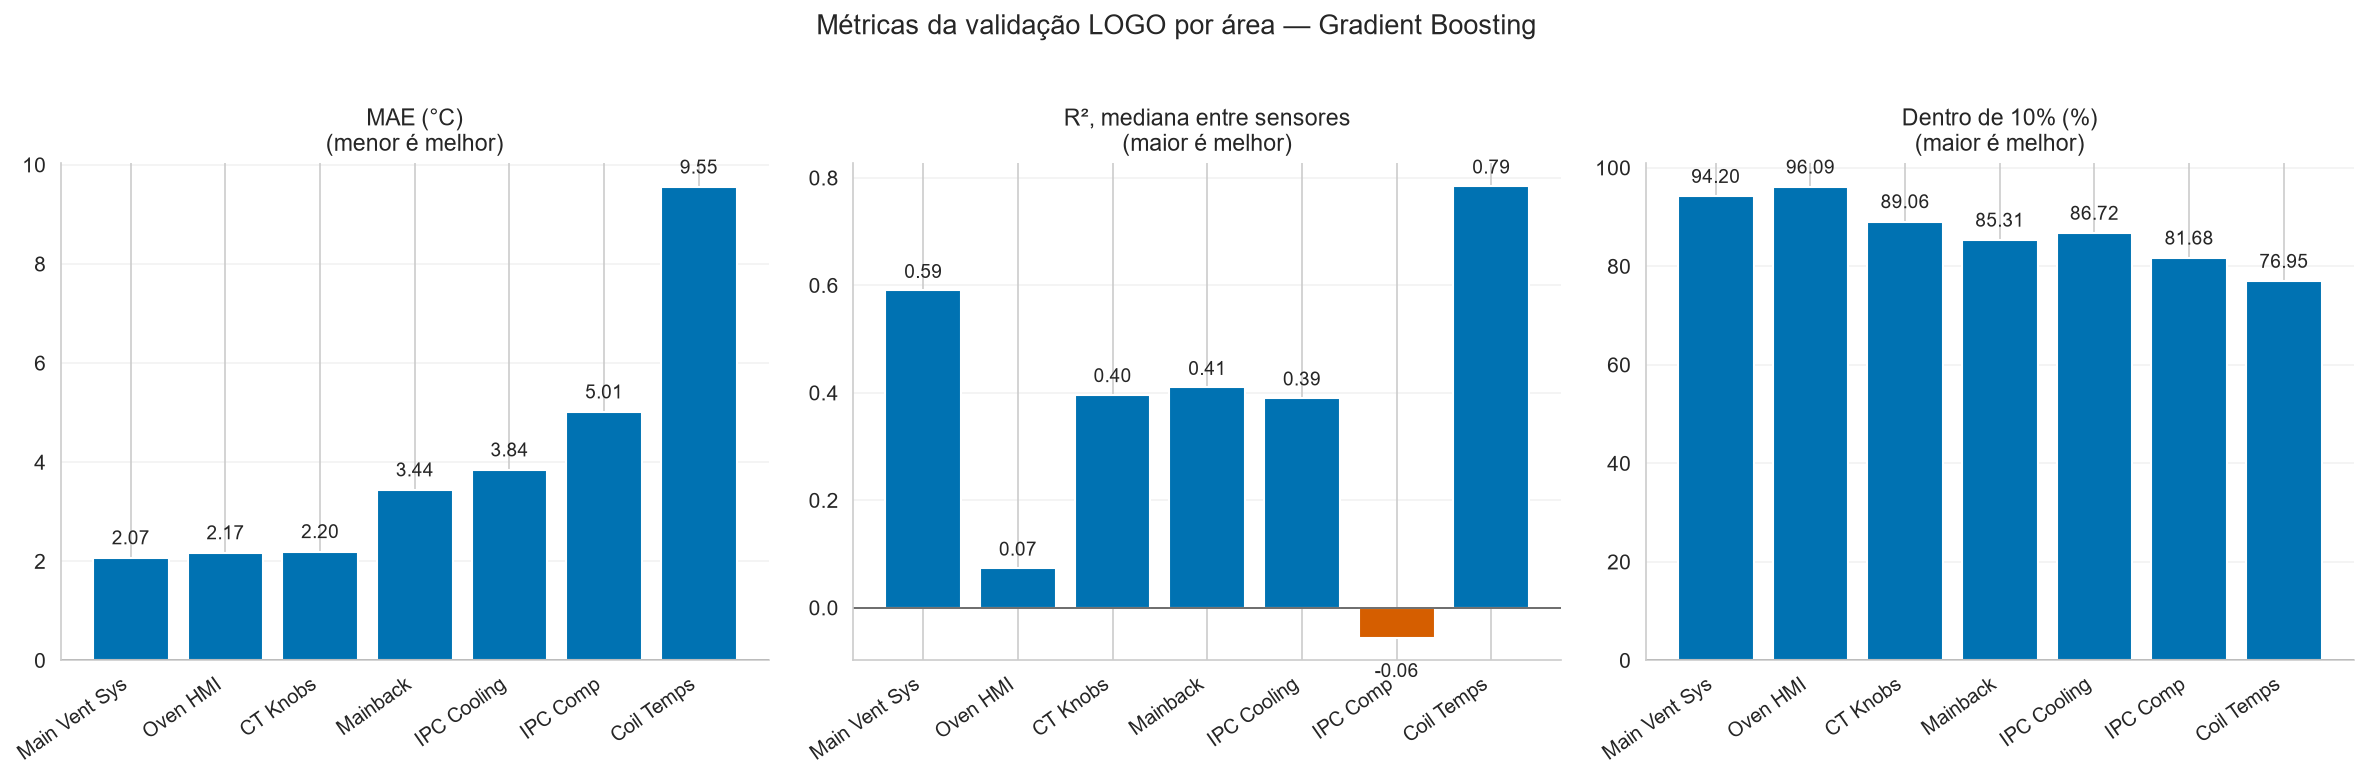

Figura salva em: ../assets/graficos/modelo_candidato_logo_metricas.png


In [9]:
# ------------------------------------------------------------
# Figura 24 -- metricas da validacao LOGO, por area
# ------------------------------------------------------------
ORDEM_AREAS = comparativo_logo.sort_values("MAE_logo")["setor"].tolist()
tabela_ord = comparativo_logo.set_index("setor").loc[ORDEM_AREAS]

ROTULOS_AREA = {
    "mainback": "Mainback", "coil_temps": "Coil Temps",
    "main_vent_sys": "Main Vent Sys", "ct_knobs": "CT Knobs",
    "ipc_comp": "IPC Comp", "ipc_cooling": "IPC Cooling",
    "oven_hmi": "Oven HMI",
}
rotulos_x = [ROTULOS_AREA[a] for a in ORDEM_AREAS]

METRICAS_LOGO = ["MAE_logo", "R2_logo_mediana", "dentro_de_10%_logo"]
TITULOS = ["MAE (\u00b0C)\n(menor \u00e9 melhor)",
           "R\u00b2, mediana entre sensores\n(maior \u00e9 melhor)",
           "Dentro de 10% (%)\n(maior \u00e9 melhor)"]

figura, eixos = plt.subplots(1, 3, figsize=(16, 5))

for eixo, metrica, titulo in zip(eixos, METRICAS_LOGO, TITULOS):
    valores = tabela_ord[metrica].values
    if metrica == "dentro_de_10%_logo":
        valores = valores * 100
    cores = ["#0072B2" if v >= 0 else "#D55E00" for v in valores]
    barras = eixo.bar(range(len(rotulos_x)), valores, color=cores,
                      edgecolor="white", linewidth=1.0)
    for barra, valor in zip(barras, valores):
        eixo.text(barra.get_x() + barra.get_width() / 2,
                  barra.get_height() + (abs(valores).max() * 0.02 if valor >= 0 else -abs(valores).max() * 0.06),
                  f"{valor:.2f}", ha="center",
                  va="bottom" if valor >= 0 else "top", fontsize=9)
    eixo.set_xticks(range(len(rotulos_x)))
    eixo.set_xticklabels(rotulos_x, rotation=35, ha="right", fontsize=9.5)
    eixo.set_title(titulo, fontsize=11)
    eixo.grid(axis="y", alpha=0.25)
    eixo.set_axisbelow(True)
    eixo.axhline(0, color="#555555", linewidth=0.8)
    for lado in ("top", "right"):
        eixo.spines[lado].set_visible(False)

figura.suptitle("M\u00e9tricas da valida\u00e7\u00e3o LOGO por \u00e1rea \u2014 Gradient Boosting",
                fontsize=13, y=1.03)
figura.tight_layout()

CAMINHO_LOGO_BARRAS = "../assets/graficos/modelo_candidato_logo_metricas.png"
figura.savefig(CAMINHO_LOGO_BARRAS, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

print(f"Figura salva em: {CAMINHO_LOGO_BARRAS}")


## 9. Modelo candidato — consolidação e escolha

As Células 1 a 8 treinaram e avaliaram o Gradient Boosting nos sete setores. Esta
seção fecha a etapa de modelagem: coloca lado a lado os resultados de teste dos
**três** algoritmos testados pelo grupo — Gradient Boosting (este notebook),
Decision Tree (`Decision_tree_regre.ipynb`) e Random Forest
(`Random_for_regre.ipynb`) — e formaliza qual deles segue como modelo candidato.

A comparação é legítima porque os três notebooks partem exatamente da mesma base:
mesmas sete planilhas wide, mesma regra de cobertura mínima de termopar (50%),
mesma padronização de categorias, mesma codificação ordinal, mesma semente (42) e
mesma divisão 70/20/10. A única coisa que varia é o algoritmo.

**Por que os números estão fixados em código nesta célula:** os três modelos vivem
em notebooks separados, e reexecutar os dois outros aqui duplicaria alguns minutos
de treino sem mudar resultado — a semente é fixa. Os valores abaixo são transcritos
das Células 8 (Gradient Boosting e Decision Tree) e 14 (Random Forest), e podem ser
reconferidos abrindo cada notebook.

**Critério de escolha:** o modelo candidato é o que vence na maioria das cinco
métricas médias entre setores. A célula conta essas vitórias em vez de declarar o
vencedor por inspeção, para que o critério fique explícito e o resultado mude
sozinho caso os notebooks sejam retreinados com outros dados.

A figura gerada nesta célula é a Figura 18 da Seção 4.3 da documentação.

COMPARATIVO ENTRE MODELOS — médias entre os sete setores (conjunto de teste)
                      MAE    RMSE      R2  MAPE_%  dentro_de_10%
modelo                                                          
Gradient Boosting  3.9214  5.4082 -6.5937  5.0350         0.8639
Decision Tree      4.7247  8.0204  0.1561  6.0448         0.8552
Random Forest      4.8818  7.1831  0.2825  6.5396         0.7983

Métricas em que cada modelo é o melhor:
 -> Gradient Boosting    4/5  MAE, RMSE, MAPE_%, dentro_de_10%
    Decision Tree        0/5  —
 -> Random Forest        1/5  R2

Modelo candidato eleito: Gradient Boosting (4 das 5 métricas)

Gap médio de MAE treino -> teste (leitura de superajuste, risco R03):
modelo
Gradient Boosting    2.9812
Decision Tree        2.8026


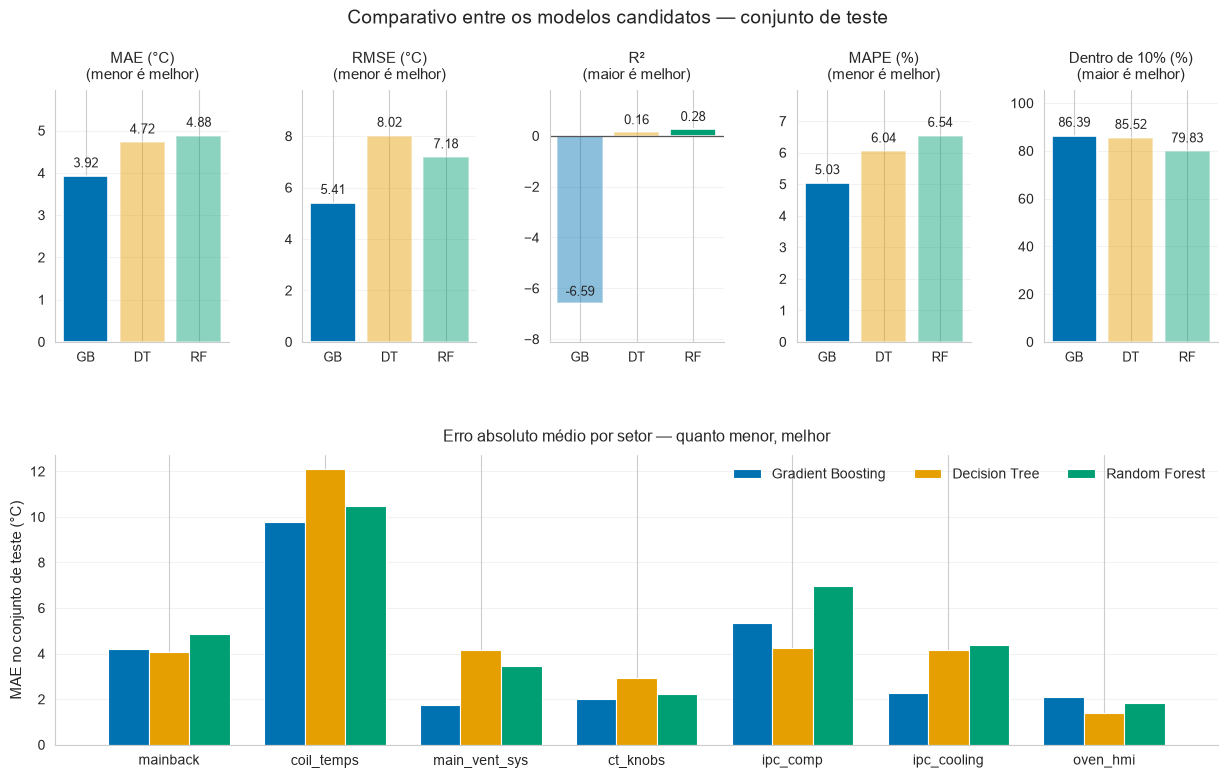


Figura salva em: ../assets/graficos/modelo_candidato_comparativo.png


In [10]:
# ============================================================
# CÉLULA 9 — MODELO CANDIDATO: CONSOLIDAÇÃO E EXPLICABILIDADE
#
# Reúne, em uma única tabela, os resultados de teste já registrados
# pelos três notebooks de modelagem e formaliza a escolha do modelo
# candidato. Os números vêm das Células 8 deste notebook, do
# `Decision_tree_regre.ipynb` e do `Random_for_regre.ipynb` — todos
# treinados sobre a mesma base, com a mesma semente (42) e a mesma
# divisão 70/20/10, de modo que a comparação é direta.
# ============================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SETORES = ["mainback", "coil_temps", "main_vent_sys", "ct_knobs",
           "ipc_comp", "ipc_cooling", "oven_hmi"]

# Resultados de teste por setor, na ordem de SETORES.
RESULTADOS_REGISTRADOS = {
    "Gradient Boosting": {
        "MAE_treino":    [0.4022, 2.0759, 0.2538, 0.4513, 1.8774, 1.3580, 0.1623],
        "MAE":           [4.1886, 9.7874, 1.7421, 2.0201, 5.3522, 2.2720, 2.0871],
        "RMSE":          [7.1346, 12.8209, 2.4648, 2.4379, 6.8857, 2.9370, 3.1767],
        "R2":            [-44.7807, 0.1012, -0.8404, -0.1124, -0.2312, -0.1258, -0.1668],
        "MAPE_%":        [7.9551, 7.3793, 2.0642, 4.0907, 6.6997, 3.6873, 3.3687],
        "dentro_de_10%": [0.8167, 0.7292, 0.9762, 0.9722, 0.7197, 0.9583, 0.8750],
    },
    "Decision Tree": {
        "MAE_treino":    [2.0205, 1.9606, 3.4029, 2.3523, 1.1440, 1.5437, 1.0305],
        "MAE":           [4.0896, 12.0926, 4.1596, 2.9172, 4.2432, 4.1770, 1.3934],
        "RMSE":          [7.5233, 23.5460, 5.9492, 3.8445, 4.9872, 8.4797, 1.8126],
        "R2":            [0.1873, 0.6172, 0.4891, 0.0804, -1.0032, 0.1085, 0.6134],
        "MAPE_%":        [6.8689, 10.1155, 4.9891, 6.1632, 6.1407, 5.5869, 2.4493],
        "dentro_de_10%": [0.8364, 0.7250, 0.8909, 0.8030, 0.8811, 0.8500, 1.0000],
    },
    "Random Forest": {
        "MAE_treino":    [np.nan] * 7,   # não registrado na Célula 8 daquele notebook
        "MAE":           [4.8575, 10.4689, 3.4369, 2.2319, 6.9593, 4.3939, 1.8242],
        "RMSE":          [7.6796, 15.3964, 5.2962, 3.0248, 8.3161, 8.3062, 2.2625],
        "R2":            [0.1905, 0.8463, 0.5902, 0.4200, -0.6802, 0.2135, 0.3975],
        "MAPE_%":        [8.0575, 9.3973, 4.1194, 4.7612, 10.4481, 5.8409, 3.1525],
        "dentro_de_10%": [0.7091, 0.6750, 0.8545, 0.8636, 0.6108, 0.8750, 1.0000],
    },
}

METRICAS = ["MAE", "RMSE", "R2", "MAPE_%", "dentro_de_10%"]
# True = quanto menor, melhor.
MENOR_E_MELHOR = {"MAE": True, "RMSE": True, "R2": False,
                  "MAPE_%": True, "dentro_de_10%": False}

CORES = {"Gradient Boosting": "#0072B2",
         "Decision Tree":     "#E69F00",
         "Random Forest":     "#009E73"}


def tabela_por_setor(resultados, setores):
    """Empilha os resultados dos três modelos em uma tabela longa."""
    linhas = []
    for modelo, metricas in resultados.items():
        for i, setor in enumerate(setores):
            linha = {"modelo": modelo, "setor": setor}
            linha.update({m: metricas[m][i] for m in metricas})
            linhas.append(linha)
    return pd.DataFrame(linhas)


def medias_entre_setores(tabela, metricas):
    """Média de cada métrica entre os sete setores, por modelo."""
    return (tabela.groupby("modelo", sort=False)[metricas]
                  .mean()
                  .loc[list(RESULTADOS_REGISTRADOS)])


def eleger_candidato(medias, menor_e_melhor):
    """Conta em quantas métricas cada modelo é o melhor."""
    vitorias = {modelo: [] for modelo in medias.index}
    for metrica, menor in menor_e_melhor.items():
        vencedor = medias[metrica].idxmin() if menor else medias[metrica].idxmax()
        vitorias[vencedor].append(metrica)
    return vitorias


por_setor = tabela_por_setor(RESULTADOS_REGISTRADOS, SETORES)
medias = medias_entre_setores(por_setor, METRICAS)
vitorias = eleger_candidato(medias, MENOR_E_MELHOR)

print("=" * 78)
print("COMPARATIVO ENTRE MODELOS — médias entre os sete setores (conjunto de teste)")
print("=" * 78)
print(medias.round(4).to_string())

print("\nMétricas em que cada modelo é o melhor:")
for modelo, metricas_vencidas in vitorias.items():
    marcador = "->" if metricas_vencidas else "  "
    print(f" {marcador} {modelo:20s} {len(metricas_vencidas)}/5  "
          f"{', '.join(metricas_vencidas) if metricas_vencidas else '—'}")

CANDIDATO = max(vitorias, key=lambda m: len(vitorias[m]))
print(f"\nModelo candidato eleito: {CANDIDATO} "
      f"({len(vitorias[CANDIDATO])} das 5 métricas)")

# Superajuste: distância entre o erro de treino e o de teste.
gap = (medias.loc[["Gradient Boosting", "Decision Tree"], "MAE"]
       - por_setor[por_setor.modelo.isin(["Gradient Boosting", "Decision Tree"])]
         .groupby("modelo", sort=False)["MAE_treino"].mean())
print("\nGap médio de MAE treino -> teste (leitura de superajuste, risco R03):")
print(gap.round(4).to_string())


# ------------------------------------------------------------
# Figura 18 — comparativo de métricas entre os três modelos
# ------------------------------------------------------------
def grafico_comparativo(medias, por_setor, setores, metricas, menor_e_melhor,
                        cores, caminho):
    rotulos = {"MAE": "MAE (°C)", "RMSE": "RMSE (°C)", "R2": "R²",
               "MAPE_%": "MAPE (%)", "dentro_de_10%": "Dentro de 10% (%)"}
    figura = plt.figure(figsize=(15, 8.5))
    grade = figura.add_gridspec(2, 5, height_ratios=[1, 1.15], hspace=0.42,
                                wspace=0.42)
    modelos = list(medias.index)

    for coluna, metrica in enumerate(metricas):
        eixo = figura.add_subplot(grade[0, coluna])
        valores = medias[metrica].copy()
        if metrica == "dentro_de_10%":
            valores = valores * 100
        melhor = valores.idxmin() if menor_e_melhor[metrica] else valores.idxmax()

        barras = eixo.bar(range(len(modelos)), valores.values,
                          color=[cores[m] for m in modelos],
                          edgecolor="white", linewidth=1.2)
        for barra, modelo in zip(barras, modelos):
            barra.set_alpha(1.0 if modelo == melhor else 0.45)
        for barra, valor in zip(barras, valores.values):
            eixo.text(barra.get_x() + barra.get_width() / 2,
                      barra.get_height() + abs(valores.values).max() * 0.03,
                      f"{valor:.2f}", ha="center", va="bottom", fontsize=9)

        seta = "menor é melhor" if menor_e_melhor[metrica] else "maior é melhor"
        eixo.set_title(f"{rotulos[metrica]}\n({seta})", fontsize=10.5, pad=8)
        eixo.set_xticks(range(len(modelos)))
        eixo.set_xticklabels(["GB", "DT", "RF"], fontsize=9.5)
        eixo.margins(y=0.22)
        eixo.grid(axis="y", alpha=0.25)
        eixo.set_axisbelow(True)
        for lado in ("top", "right"):
            eixo.spines[lado].set_visible(False)
        if valores.min() < 0:
            eixo.axhline(0, color="#555555", linewidth=0.9)

    eixo_setor = figura.add_subplot(grade[1, :])
    largura = 0.26
    posicoes = np.arange(len(setores))
    for i, modelo in enumerate(modelos):
        serie = (por_setor[por_setor.modelo == modelo]
                 .set_index("setor").loc[setores, "MAE"])
        eixo_setor.bar(posicoes + (i - 1) * largura, serie.values, largura,
                       label=modelo, color=cores[modelo],
                       edgecolor="white", linewidth=0.8)
    eixo_setor.set_xticks(posicoes)
    eixo_setor.set_xticklabels(setores, fontsize=10)
    eixo_setor.set_ylabel("MAE no conjunto de teste (°C)", fontsize=10.5)
    eixo_setor.set_title("Erro absoluto médio por setor — quanto menor, melhor",
                         fontsize=11.5, pad=10)
    eixo_setor.legend(frameon=False, ncol=3, fontsize=10, loc="upper right")
    eixo_setor.grid(axis="y", alpha=0.25)
    eixo_setor.set_axisbelow(True)
    for lado in ("top", "right"):
        eixo_setor.spines[lado].set_visible(False)

    figura.suptitle("Comparativo entre os modelos candidatos — conjunto de teste",
                    fontsize=13.5, y=0.975)
    figura.savefig(caminho, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    return caminho


CAMINHO_COMPARATIVO = "../assets/graficos/modelo_candidato_comparativo.png"

grafico_comparativo(medias, por_setor, SETORES, METRICAS, MENOR_E_MELHOR,
                    CORES, CAMINHO_COMPARATIVO)
print()
print(f"Figura salva em: {CAMINHO_COMPARATIVO}")

### 9.1. Explicabilidade do modelo candidato

O `MultiOutputRegressor` treina um regressor por termopar, então cada um tem sua
própria importância de variáveis — informação que os notebooks de Random Forest e
Decision Tree não produzem, porque ali um único modelo cobre todos os alvos da área.

A célula abaixo consolida essa matriz em duas leituras: a importância **média** entre
os termopares da área, e o termopar em que cada variável mais pesa. Os valores são os
da Célula 5 (área `mainback`).

**Ressalva de leitura:** pela H2 (Seção 4.2.4), as sete configurações estão
confundidas no desenho experimental — `losses` é redundante com `deflector_hole`.
Modelos de árvore distribuem o crédito preditivo de forma arbitrária entre variáveis
redundantes, então esta figura descreve **como o modelo decide**, não **como o fogão
aquece**. O título do gráfico carrega esse aviso.

Gera a Figura 19 da Seção 4.3 da documentação.

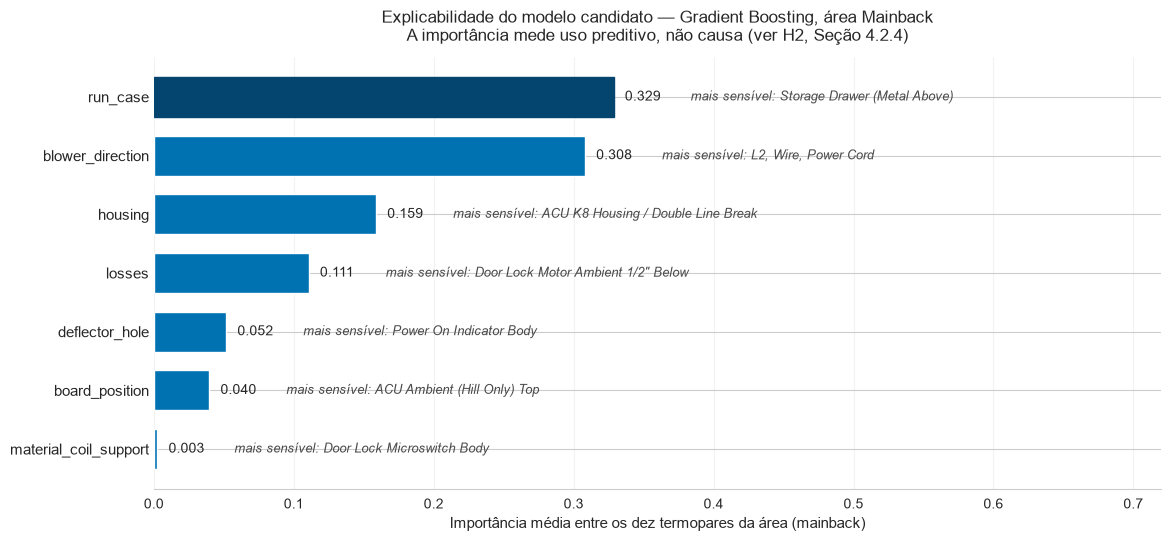


Figura salva em: ../assets/graficos/modelo_candidato_explicabilidade.png


In [11]:
# ------------------------------------------------------------
# Figura 19 — explicabilidade do modelo candidato
# ------------------------------------------------------------
# Importâncias médias entre os dez termopares de `mainback` (Célula 5) e o
# termopar em que cada variável mais pesa — a leitura por sensor só existe
# porque o MultiOutputRegressor treina um GBR por termopar.
IMPORTANCIA_MAINBACK = {
    "run_case":              (0.3286, "Storage Drawer (Metal Above)", 0.836),
    "blower_direction":      (0.3081, "L2, Wire, Power Cord", 0.512),
    "housing":               (0.1588, "ACU K8 Housing / Double Line Break", 0.289),
    "losses":                (0.1107, "Door Lock Motor Ambient 1/2\" Below", 0.198),
    "deflector_hole":        (0.0517, "Power On Indicator Body", 0.120),
    "board_position":        (0.0396, "ACU Ambient (Hill Only) Top", 0.358),
    "material_coil_support": (0.0025, "Door Lock Microswitch Body", 0.014),
}


def grafico_explicabilidade(importancias, caminho):
    variaveis = list(importancias)[::-1]
    medias_imp = [importancias[v][0] for v in variaveis]
    sensores = [importancias[v][1] for v in variaveis]

    figura, eixo = plt.subplots(figsize=(13, 5.6))
    barras = eixo.barh(variaveis, medias_imp, color="#0072B2",
                       edgecolor="white", linewidth=1.0, height=0.68)
    barras[-1].set_color("#04456F")

    for barra, valor, sensor in zip(barras, medias_imp, sensores):
        eixo.text(valor + 0.008, barra.get_y() + barra.get_height() / 2,
                  f"{valor:.3f}", va="center", fontsize=10)
        eixo.text(valor + 0.055, barra.get_y() + barra.get_height() / 2,
                  f"mais sensível: {sensor}", va="center", fontsize=9,
                  color="#4A4A4A", style="italic")

    eixo.set_xlim(0, 0.72)
    eixo.set_xlabel("Importância média entre os dez termopares da área (mainback)",
                    fontsize=10.5)
    eixo.set_title("Explicabilidade do modelo candidato — Gradient Boosting, área "
                   "Mainback\nA importância mede uso preditivo, não causa "
                   "(ver H2, Seção 4.2.4)", fontsize=12, pad=12)
    eixo.grid(axis="x", alpha=0.25)
    eixo.set_axisbelow(True)
    for lado in ("top", "right", "left"):
        eixo.spines[lado].set_visible(False)
    eixo.tick_params(axis="y", length=0, labelsize=10.5)

    figura.savefig(caminho, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    return caminho


CAMINHO_EXPLICABILIDADE = "../assets/graficos/modelo_candidato_explicabilidade.png"

grafico_explicabilidade(IMPORTANCIA_MAINBACK, CAMINHO_EXPLICABILIDADE)
print()
print(f"Figura salva em: {CAMINHO_EXPLICABILIDADE}")

### 9.2. Validação da explicabilidade com SHAP

A importância por impureza (Seção 9.1) tem duas limitações: é adimensional — compara
variáveis entre si, mas não diz "em quantos graus" cada uma pesa — e, como qualquer
importância de árvore, distribui crédito de forma arbitrária entre variáveis
correlacionadas (H2, Seção 4.2.4). Esta seção recalcula a mesma leitura com **SHAP**
(SHapley Additive exPlanations), aplicado via `TreeExplainer` a cada um dos dez
`GradientBoostingRegressor` de `mainback` (Célula 5).

A vantagem é dupla: o valor SHAP tem a mesma unidade do alvo (°C) — dá para dizer
"`blower_direction` desloca a previsão em ~3 °C, em média", não só "pesa 0,31" — e o
método é aditivo por construção: a soma das contribuições de uma linha bate
exatamente com a diferença entre a predição e a média do modelo, sem depender de
como a árvore particiona o espaço internamente.

A Figura 20 mostra o resultado, na mesma agregação da Figura 19: média de |SHAP|
entre os dez termopares, com o termopar mais sensível a cada variável.


Importancia SHAP media (|valor SHAP| em graus C, entre os 10 termopares):
blower_direction         3.0943
run_case                 2.8262
housing                  1.9743
losses                   1.6116
board_position           0.4867
deflector_hole           0.4565
material_coil_support    0.0826

Termopar mais sensivel a cada variavel (SHAP):
   blower_direction         -> ACU Ambient (Hill Only) Top (6.566)
   run_case                 -> Storage Drawer (Metal Above) (11.463)
   housing                  -> L2, Wire, Power Cord (3.804)
   losses                   -> Convect Motor Winding (2.579)
   board_position           -> ACU Ambient (Hill Only) Top (4.342)
   deflector_hole           -> Storage Drawer (Metal Above) (0.861)
   material_coil_support    -> Door Lock Microswitch Body (0.283)

Comparacao impureza (Figura 19) x SHAP (Figura 20):
                       impureza  SHAP (graus C)  rank impureza  rank SHAP
blower_direction         0.3081          3.0943              2       

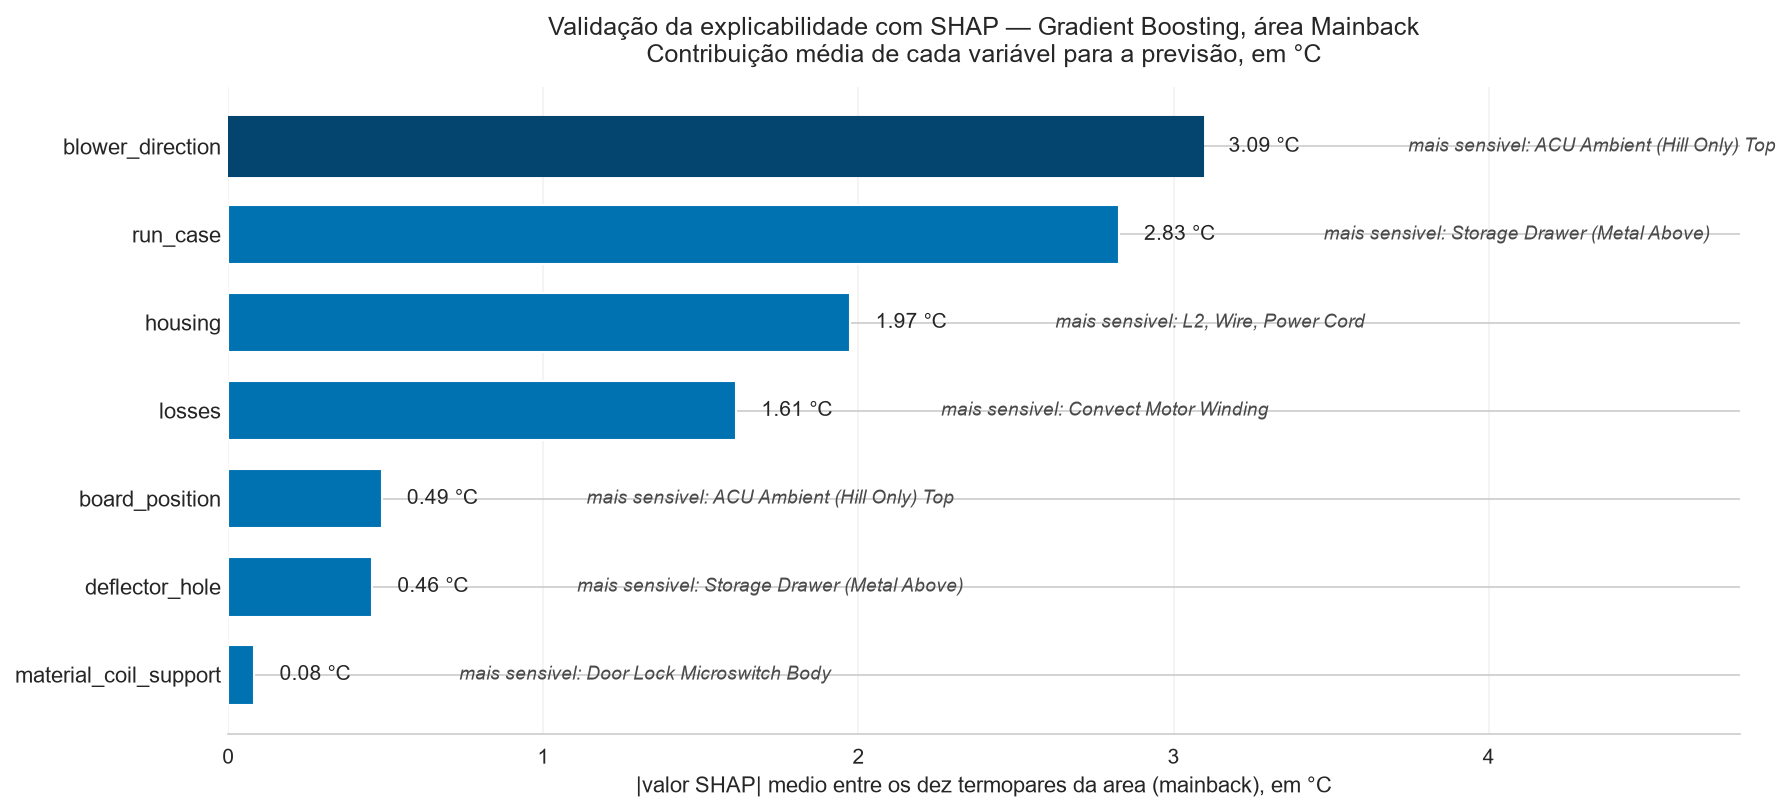

In [11]:
# ------------------------------------------------------------
# Figura 20 -- validacao da explicabilidade com SHAP
# ------------------------------------------------------------
# TreeExplainer roda por termopar (cada GBR do MultiOutputRegressor e
# independente) sobre as 32 linhas de `mainback`; agrega |SHAP| por coluna
# one-hot de volta a variavel original (mesma logica de `importancias_por_alvo`)
# e depois tira a media entre os dez termopares -- mesma leitura da Figura 19,
# mas em graus Celsius em vez de importancia adimensional.
import shap

def importancia_shap_por_alvo(modelo_multioutput, X, independentes, alvos):
    """Matriz termopar x variavel com a media de |SHAP| por termopar,
    somando as colunas one-hot de volta a variavel original."""
    shap_por_alvo = {}
    for alvo, estimador in zip(alvos, modelo_multioutput.estimators_):
        valores_shap = shap.TreeExplainer(estimador).shap_values(X)
        shap_por_alvo[alvo] = np.abs(valores_shap).mean(axis=0)

    bruta = pd.DataFrame(shap_por_alvo, index=X.columns).T

    def variavel_original(coluna):
        candidatos = [v for v in independentes if coluna.startswith(v + "_")]
        return max(candidatos, key=len)

    mapa_variavel = {coluna: variavel_original(coluna) for coluna in X.columns}
    return bruta.T.groupby(mapa_variavel).sum().T


matriz_shap_mainback = importancia_shap_por_alvo(
    modelo, X, VARIAVEIS_INDEPENDENTES, VARIAVEIS_ALVO
)
shap_mainback = matriz_shap_mainback.mean().sort_values(ascending=False)

print("Importancia SHAP media (|valor SHAP| em graus C, entre os 10 termopares):")
print(shap_mainback.round(4).to_string())

print("\nTermopar mais sensivel a cada variavel (SHAP):")
for variavel in shap_mainback.index:
    alvo = matriz_shap_mainback[variavel].idxmax()
    print(f"   {variavel:24s} -> {alvo} ({matriz_shap_mainback.loc[alvo, variavel]:.3f})")

comparacao_shap_impureza = pd.DataFrame({
    "impureza": importancia,
    "SHAP (graus C)": shap_mainback,
}).sort_values("SHAP (graus C)", ascending=False)
comparacao_shap_impureza["rank impureza"] = comparacao_shap_impureza["impureza"].rank(ascending=False).astype(int)
comparacao_shap_impureza["rank SHAP"] = comparacao_shap_impureza["SHAP (graus C)"].rank(ascending=False).astype(int)

print("\nComparacao impureza (Figura 19) x SHAP (Figura 20):")
print(comparacao_shap_impureza.round(4).to_string())


def grafico_shap(shap_medio, matriz_shap, caminho):
    variaveis = list(shap_medio.index)[::-1]
    valores = [shap_medio[v] for v in variaveis]
    sensores = [matriz_shap[v].idxmax() for v in variaveis]

    figura, eixo = plt.subplots(figsize=(13, 5.6))
    barras = eixo.barh(variaveis, valores, color="#0072B2",
                       edgecolor="white", linewidth=1.0, height=0.68)
    barras[-1].set_color("#04456F")

    for barra, valor, sensor in zip(barras, valores, sensores):
        eixo.text(valor + 0.08, barra.get_y() + barra.get_height() / 2,
                  f"{valor:.2f} \u00b0C", va="center", fontsize=10)
        eixo.text(valor + 0.65, barra.get_y() + barra.get_height() / 2,
                  f"mais sensivel: {sensor}", va="center", fontsize=9,
                  color="#4A4A4A", style="italic")

    eixo.set_xlim(0, max(valores) * 1.55)
    eixo.set_xlabel("|valor SHAP| medio entre os dez termopares da area (mainback), em \u00b0C",
                    fontsize=10.5)
    eixo.set_title("Valida\u00e7\u00e3o da explicabilidade com SHAP \u2014 Gradient Boosting, \u00e1rea "
                   "Mainback\nContribui\u00e7\u00e3o m\u00e9dia de cada vari\u00e1vel para a previs\u00e3o, em \u00b0C",
                   fontsize=12, pad=12)
    eixo.grid(axis="x", alpha=0.25)
    eixo.set_axisbelow(True)
    for lado in ("top", "right", "left"):
        eixo.spines[lado].set_visible(False)
    eixo.tick_params(axis="y", length=0, labelsize=10.5)

    figura.savefig(caminho, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()
    return caminho


CAMINHO_SHAP = "../assets/graficos/modelo_candidato_shap.png"

grafico_shap(shap_mainback, matriz_shap_mainback, CAMINHO_SHAP)
print()
print(f"Figura salva em: {CAMINHO_SHAP}")


### 9.3. Explicabilidade SHAP nas sete áreas

A Seção 9.2 aplicou SHAP só em `mainback`, a área analisada em detalhe. Esta
seção estende a mesma leitura às sete áreas, reaproveitando os modelos já
treinados na Célula 7 — sem retreinar nada.

Como cada área opera em um patamar de temperatura diferente (de ~47 °C em
`CT Knobs` a ~124 °C em `Coil Temps`), o valor SHAP em °C não é diretamente
comparável entre áreas: uma variável "vale" mais graus numa área que já é
mais quente, mesmo que pese proporcionalmente menos. Por isso a Figura 23
normaliza cada linha para somar 100%, comparando a **participação relativa**
de cada variável dentro de cada área, no mesmo formato de mapa de calor usado
para o Random Forest (`Random_for_regre.ipynb`).


OK   mainback        (colunas one-hot: 27, alvos: 10)
OK   coil_temps      (colunas one-hot: 27, alvos: 8)
OK   main_vent_sys   (colunas one-hot: 27, alvos: 7)
OK   ct_knobs        (colunas one-hot: 27, alvos: 6)
OK   ipc_comp        (colunas one-hot: 27, alvos: 22)
OK   ipc_cooling     (colunas one-hot: 27, alvos: 4)
OK   oven_hmi        (colunas one-hot: 27, alvos: 4)

IMPORTANCIA SHAP GLOBAL (|SHAP| medio em graus C, entre os termopares de cada area)
               blower_direction  board_position  deflector_hole  housing  losses  material_coil_support  run_case
mainback                  3.094           0.487           0.456    1.974   1.612                  0.083     2.826
coil_temps                1.879           0.935           1.731    5.028  10.348                  3.592    26.327
main_vent_sys             1.025           0.091           0.794    1.141   0.950                  0.033     2.189
ct_knobs                  0.613           0.143           0.856    0.592   1.569      

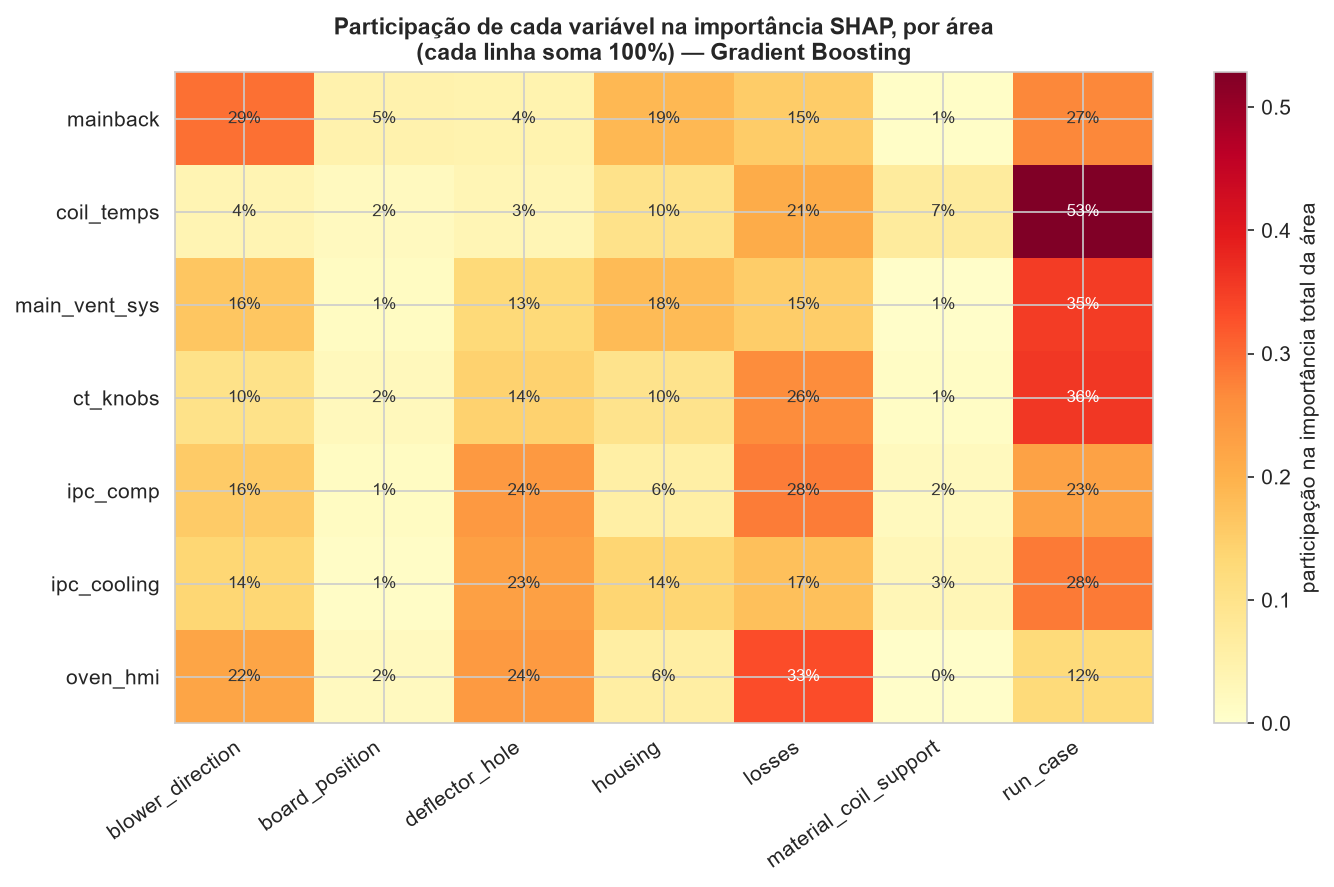

In [12]:
# ------------------------------------------------------------
# Figura 23 -- mapa de calor: participacao da importancia SHAP por area
# ------------------------------------------------------------
# Estende a Secao 9.2 (que olhava so `mainback`) para as sete areas: reusa o
# modelo ja treinado de cada setor (Celula 7) e recalcula a importancia SHAP
# com o mesmo `TreeExplainer` por termopar, normalizando cada linha para
# somar 100% -- assim a comparacao entre areas e sobre PARTICIPACAO relativa,
# nao sobre graus C absolutos (que dependem do patamar termico de cada area).
import shap

IMPORTANCIA_SHAP_POR_AREA = {}

for caminho in PLANILHAS:
    nome_area = caminho.split("/")[-1].replace("_data.csv", "")
    X_area, Y_area, alvos_area, dicionario_area, _ = preparar_area(caminho)
    modelo_area = MODELOS_POR_AREA[nome_area]["modelo"]

    matriz_shap_area = importancia_shap_por_alvo(
        modelo_area, X_area, VARIAVEIS_INDEPENDENTES, alvos_area
    )
    IMPORTANCIA_SHAP_POR_AREA[nome_area] = matriz_shap_area.mean()
    print(f"OK   {nome_area:15s} (colunas one-hot: {X_area.shape[1]}, alvos: {len(alvos_area)})")

tabela_shap_areas = pd.DataFrame(IMPORTANCIA_SHAP_POR_AREA).T

print("\n" + "=" * 100)
print("IMPORTANCIA SHAP GLOBAL (|SHAP| medio em graus C, entre os termopares de cada area)")
print("=" * 100)
print(tabela_shap_areas.round(3).to_string())

tabela_shap_norm = tabela_shap_areas.div(tabela_shap_areas.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9.5, 6))
im = ax.imshow(tabela_shap_norm.values, cmap="YlOrRd", aspect="auto", vmin=0)

ax.set_xticks(range(len(tabela_shap_norm.columns)))
ax.set_xticklabels(tabela_shap_norm.columns, rotation=35, ha="right")
ax.set_yticks(range(len(tabela_shap_norm.index)))
ax.set_yticklabels(tabela_shap_norm.index)

limite_cor = tabela_shap_norm.values.max()
for i in range(tabela_shap_norm.shape[0]):
    for j in range(tabela_shap_norm.shape[1]):
        valor = tabela_shap_norm.values[i, j]
        cor_texto = "white" if valor > limite_cor * 0.6 else "#333333"
        ax.text(j, i, f"{valor:.0%}", ha="center", va="center", fontsize=8, color=cor_texto)

ax.set_title("Participa\u00e7\u00e3o de cada vari\u00e1vel na import\u00e2ncia SHAP, por \u00e1rea\n(cada linha soma 100%) \u2014 Gradient Boosting",
             fontsize=11, fontweight="bold")
fig.colorbar(im, ax=ax, label="participa\u00e7\u00e3o na import\u00e2ncia total da \u00e1rea")
plt.tight_layout()

CAMINHO_SHAP_HEATMAP = "../assets/graficos/modelo_candidato_shap_por_area.png"
fig.savefig(CAMINHO_SHAP_HEATMAP, dpi=150, bbox_inches="tight", facecolor="white")
plt.show()

print("\nVariavel mais importante por area:")
print(tabela_shap_norm.idxmax(axis=1).to_string())
print(f"\nFigura salva em: {CAMINHO_SHAP_HEATMAP}")
